# Commons

In [ ]:
from __future__ import annotations

from pathlib import Path
import os

import numpy as np
import pandas as pd
import pydicom
import torch
from skimage.transform import resize
from torch.utils.data import DataLoader, Dataset

### Data functions ###

def ct_normalization(img, meta):
    """
    Normalizes the HU range to [0, 1].
    We adjust from -1024 (air) to 3072 (dense tissue) to cover a wide range
    to highlight anatomical details.
    """
    def scale(img, meta, slope=1.0, intersept=-1024):
        MIN_B = -1024
        MAX_B = 3072

        slope = float(meta.get("Rescale Slope", slope))
        intersept = float(meta.get("Rescale Intercept", intersept))
        
        img = np.asarray(img) * slope + intersept  # Apply the scale and offset transformation
        img = resize(img, (256, 256), preserve_range=True)  # Ensure all images have the same size
        img = (img - MIN_B) / (MAX_B - MIN_B)  # Scale to [0, 1]
        if img.ndim == 2:
            img = np.expand_dims(img, axis=0)
        return img.astype(np.float32)
    
    return scale(img, meta)

def _read_dicom(path: Path) -> np.ndarray:
    
    ds = pydicom.dcmread(path)  # Read DICOM file and convert to a numpy array
    metadata = {}
    for element in ds:
            if getattr(element, "name", None) == "Pixel Data":
                continue
            try:
                name = str(element.name)
                value = element.value
                if value is None:
                    continue
                metadata[name] = str(value)
            except Exception:
                continue

    return ct_normalization(ds.pixel_array, metadata)


class LDCTDataset(Dataset):
    def __init__(
        self,
        df: pd.DataFrame,
        model_type: str = "model",
    ) -> None:
        """
        Args:
            df: DataFrame with either:
            transform: Optional transform to be applied on a sample.
            model_type: "model" or "vae", used to determine how to process the data.
        """
        self.data = df.dropna()
        self.model_type = model_type
        self.cache_saving = False

        self._preprocess()

    def _preprocess(self) -> pd.DataFrame:
        rows = []

        unwrap_dir = lambda path: sorted([str(path / fname) for fname in os.listdir(path) if (path / fname).is_file()])

        idx = 0
        for row in self.data.itertuples(index=False):
            sdct_dir = Path(row.SDCT)
            sdct_files = unwrap_dir(sdct_dir)
            
            if self.model_type == "model":
                ldct_dir = Path(row.LDCT)
                ldct_files = unwrap_dir(ldct_dir)
                rows.extend([
                    {'Case': row.Case, 'SDCT': s, 'LDCT': l, 'split_count': len(ldct_files), 'split_idx': idxS} 
                    for idxS, (s, l) in enumerate(zip(sdct_files, ldct_files))
                ])
            
            elif self.model_type == "vae":
                rows.extend([
                    {'Case': row.Case, 'SDCT': s, 'split_count': len(sdct_files), 'split_idx': idxS} 
                    for idxS, s in enumerate(sdct_files)
                ])
            idx += 1
                    
        df = pd.DataFrame(rows)
        self.data = df.to_dict("records")
        self.size = len(self.data)
    
    def load_dicom(self, idx: int, modality: str = "SDCT") -> dict:
        row = self.data[idx]
        cache_path = "./cache/tensors"
        img = _read_dicom(Path(row[modality]))
        tensor = torch.as_tensor(img).float().contiguous()  # Shape: (1, H, W)
        return tensor
    
    def __len__(self) -> int:
        return self.size

    def __getitem__(self, idx: int) -> dict:
        row = self.data[idx]
        sample = {'Case': row['Case']}
        sample['split_idx'] = row['split_idx']
        sample['size'] = (256, 256)
        if self.model_type == "model":
            sample['SDCT'] = self.load_dicom(idx, modality='SDCT')
            sample['LDCT'] = self.load_dicom(idx, modality='LDCT')
        elif self.model_type == "vae":
            sample['SDCT'] = self.load_dicom(idx, modality='SDCT')
        
        return sample

In [3]:
def save_checkpoint(state: dict, path: Path) -> None:
    if torch is None:
        raise RuntimeError("save_checkpoint requires PyTorch to be installed.")
    path.parent.mkdir(parents=True, exist_ok=True)
    torch.save(state, path)

def verify_and_create_folder(path: Path) -> Path:
    import glob
    
    # Find all existing folders matching pattern test_monai_*
    existing_folders = glob.glob(str(path / "test_monai_*"))
    existing_numbers = []
    
    for folder in existing_folders:
        try:
            number = int(folder[32:])
            existing_numbers.append(number)
        except:
            pass

    # Get the last number or start at 0
    last_number = max(existing_numbers) if existing_numbers else 0
    new_number = last_number + 1
    
    # Create new folder
    new_folder = path / f"test_monai_{new_number}"
    Path(new_folder).mkdir(parents=True, exist_ok=True)
    return new_folder

def save_epoch_metrics(epoch: int, avg_loss: float, csv_path: Path) -> None:
    """
    Save epoch metrics to a CSV file.
    
    Args:
        epoch: Current epoch number
        avg_loss: Average loss for the epoch
        csv_path: Path to save the CSV file
    """
    import csv
    csv_path = csv_path / "metrics.csv"
    csv_path.parent.mkdir(parents=True, exist_ok=True)
    
    # Check if file exists to determine if we need to write headers
    file_exists = csv_path.exists()
    
    with open(csv_path, 'a', newline='') as csvfile:
        fieldnames = ['epoch', 'recon_loss', 'kl_loss', 'avg_loss']
        writer = csv.DictWriter(csvfile, fieldnames=fieldnames)
        
        # Write header only if file is new
        if not file_exists:
            writer.writeheader()
        
        writer.writerow({
            'epoch': epoch,
            'avg_loss': f"{avg_loss:.4f}"
        }) 

import os
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Test

## Model loader

In [101]:
from diffusers import UNet2DModel
import torch
from monai.networks.nets import AutoencoderKL

# Cargar modelo desde el checkpoints/
vae_state_dict = torch.load("./checkpoints/VaeMonai/monai_7/vae_best.pt")
# --- 1. Configuración de Hardware y Modelo ---
torch.cuda.empty_cache()

vae = AutoencoderKL(
    spatial_dims=2,
    in_channels=1,
    out_channels=1,
    channels=(128, 256, 512, 512),
    latent_channels=4, 
    num_res_blocks=2,
    attention_levels=(False, False, True, True), 
).to(device)

vae.load_state_dict(vae_state_dict["model"])
vae.eval()
vae.requires_grad_(False)

# Initialize a UNet2D model for flow matching
model = UNet2DModel(
    sample_size=32,
    in_channels=4,
    out_channels=4,
    layers_per_block=2,       # Layers per residual block
    block_out_channels=(128, 256, 512, 512),  # Channel progression
    down_block_types=("DownBlock2D", "DownBlock2D", "AttnDownBlock2D", "AttnDownBlock2D"),
    up_block_types=("AttnUpBlock2D", "AttnUpBlock2D", "UpBlock2D", "UpBlock2D"),
    # block_out_channels=(128, 256, 256, 512, 512),  # Channel progression
    # down_block_types=("DownBlock2D", "DownBlock2D", "DownBlock2D", "AttnDownBlock2D", "AttnDownBlock2D"),
    # up_block_types=("AttnUpBlock2D", "AttnUpBlock2D", "UpBlock2D", "UpBlock2D", "UpBlock2D"),
).to(device)

# Cargar modelo desde el checkpoints/
state_dict = torch.load("./checkpoints/VaeMonaiFM/monai_4/vaeFM_best.pt", map_location=device)
model.load_state_dict(state_dict["model"])


import matplotlib.pyplot as plt
import torch
import numpy as np
# PSNR y SSIM
from skimage.metrics import peak_signal_noise_ratio as compute_psnr
from skimage.metrics import structural_similarity as compute_ssim

@torch.no_grad()
def plot_flow_inference_vae(vae, unet, batch, device, num_steps=20, show_plots=True):
    vae.eval()
    unet.eval()
    
    # 1. Preparar datos
    ldct = batch["LDCT"][:1].to(device)
    sdct = batch["SDCT"][:1].to(device)
    
    # 2. Obtener latente inicial (LDCT)
    z_t, _ = vae.encode(ldct) # Este es nuestro z_0
    # z_t = ldct # Imagen inicial (LDCT)
    
    # 3. INTEGRACIÓN DE EULER (Resolviendo la ODE)
    # Queremos ir de t=0 a t=1
    dt = 1.0 / num_steps
    
    for i in range(num_steps):
        t = torch.ones((1,), device=device) * (i / num_steps)
        # Predecir la velocidad en el punto actual
        v_pred = unet(z_t, t).sample
        # Dar un pequeño paso en esa dirección
        z_t = z_t + v_pred * dt
        
    # 4. Decodificar el resultado final y el original para comparar
    recon_sdct_flow = vae.decode(z_t) # Resultado del Flow Matching
    # recon_sdct_flow = zt # Resultado del Flow Matching
    recon_sdct_flow = torch.sigmoid(recon_sdct_flow)

    # Pasar a CPU para plotting
    ldct_img = ldct[0,0].cpu().numpy()
    sdct_img = sdct[0,0].cpu().numpy()
    flow_img = recon_sdct_flow[0,0].cpu().numpy()


    # --- CÁLCULO DE MÉTRICAS ---
    # Como usaste sigmoid, asumimos que el rango dinámico de tus imágenes es 1.0 (de 0 a 1)
    data_range = 1.0 

    psnr_val = compute_psnr(sdct_img, flow_img, data_range=data_range)
    ssim_val = compute_ssim(sdct_img, flow_img, data_range=data_range)

    if not show_plots:
        return psnr_val, ssim_val
    
    print(f"PSNR: {psnr_val:.2f} dB, SSIM: {ssim_val:.4f}")
    # 5. Crear el Plot
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    
    # Columna 1: Entrada ruidosa
    axes[0].imshow(ldct_img, cmap='gray')
    axes[0].set_title("Input (LDCT)")
    axes[0].axis('off')
    
    # Columna 2: Objetivo real
    axes[1].imshow(sdct_img, cmap='gray')
    axes[1].set_title("Target (SDCT)")
    axes[1].axis('off')
    
    # Columna 3: Resultado del Flow Matching
    axes[2].imshow(flow_img, cmap='gray')
    axes[2].set_title(f"Flow Result (Steps: {num_steps})")
    axes[2].axis('off')
    
    # Columna 4: Mapa de error (Diferencia)
    # Esto muestra qué tanto "limpió" el modelo
    error_map = np.abs(sdct_img - flow_img)
    im = axes[3].imshow(error_map, cmap='hot')
    axes[3].set_title("Absolute Error")
    axes[3].axis('off')
    plt.colorbar(im, ax=axes[3], fraction=0.046, pad=0.04)

    plt.suptitle(f"Inferencia de Flow Matching - Con VAE", fontsize=16)
    plt.tight_layout()
    plt.show()

In [6]:
@torch.no_grad()
def plot_flow_inference_vae_model(vae, unet, batch, device, num_steps=20, show_plots=True):
    # vae.eval()
    unet.eval()
    
    # 1. Preparar datos
    ldct = batch["LDCT"][:1].to(device)
    sdct = batch["SDCT"][:1].to(device)
    
    # 2. Obtener latente inicial (LDCT)
    z_t, _ = vae.encode(ldct) # Este es nuestro z_0
    z_t_copy = z_t.clone() # Guardamos una copia para comparar después
    z_1, _ = vae.encode(sdct) # Latente objetivo (SDCT)
    # z_t = ldct # Imagen inicial (LDCT)
    
    # 3. INTEGRACIÓN DE EULER (Resolviendo la ODE)
    # Queremos ir de t=0 a t=1
    dt = 1.0 / num_steps
    
    for i in range(num_steps):
        t = torch.ones((1,), device=device) * (i / num_steps)
        # Predecir la velocidad en el punto actual
        v_pred = unet(z_t, t).sample
        # Dar un pequeño paso en esa dirección
        z_t = z_t + v_pred * dt
        
    # 4. Decodificar el resultado final y el original para comparar
    recon_sdct_flow = z_t # Resultado del Flow Matching

    # Pasar a CPU para plotting
    ldct_img = z_t_copy[0].cpu().numpy()
    sdct_img = z_1[0].cpu().numpy()
    flow_img = recon_sdct_flow[0].cpu().numpy()


    # --- CÁLCULO DE MÉTRICAS ---
    # Como no use sigmoid, calculamos el rango dinámico a partir de los datos
    data_range = max(sdct_img.max(), flow_img.max()) - min(sdct_img.min(), flow_img.min())

    psnr_val = compute_psnr(sdct_img, flow_img, data_range=data_range)
    ssim_val = compute_ssim(sdct_img, flow_img, data_range=data_range, channel_axis=0)

    if not show_plots:
        return psnr_val, ssim_val
    
    print(f"PSNR: {psnr_val:.2f} dB, SSIM: {ssim_val:.4f}")
    for i in range(4):
        # 5. Crear el Plot
        fig, axes = plt.subplots(1, 4, figsize=(20, 5))
        
        # Columna 1: Entrada ruidosa
        axes[0].imshow(ldct_img[i], cmap='magma')
        axes[0].set_title("Input (LDCT)")
        axes[0].axis('off')
        
        # Columna 2: Objetivo real
        axes[1].imshow(sdct_img[i], cmap='magma')
        axes[1].set_title("Target (SDCT)")
        axes[1].axis('off')
        
        # Columna 3: Resultado del Flow Matching
        axes[2].imshow(flow_img[i], cmap='magma')
        axes[2].set_title(f"Flow Result (Steps: {num_steps})")
        axes[2].axis('off')
        
        # Columna 4: Mapa de error (Diferencia)
        # Esto muestra qué tanto "limpió" el modelo
        error_map = np.abs(sdct_img[i] - flow_img[i])
        im = axes[3].imshow(error_map, cmap='hot')
        axes[3].set_title("Absolute Error")
        axes[3].axis('off')
        plt.colorbar(im, ax=axes[3], fraction=0.046, pad=0.04)

        plt.suptitle(f"Inferencia de Flow Matching - Con VAE", fontsize=16)
        plt.tight_layout()
        plt.show()

In [7]:
model2 = UNet2DModel(
    sample_size=256,
    in_channels=1,
    out_channels=1,
    layers_per_block=2,       # Layers per residual block
    block_out_channels=(128, 256, 512, 512),  # Channel progression
    # block_out_channels=(128, 256, 256, 512, 512),  # Channel progression
    down_block_types=("DownBlock2D", "DownBlock2D", "AttnDownBlock2D", "AttnDownBlock2D"),
    up_block_types=("AttnUpBlock2D", "AttnUpBlock2D", "UpBlock2D", "UpBlock2D"),
    # down_block_types=("DownBlock2D", "DownBlock2D", "DownBlock2D", "AttnDownBlock2D", "AttnDownBlock2D"),
    # up_block_types=("AttnUpBlock2D", "AttnUpBlock2D", "UpBlock2D", "UpBlock2D", "UpBlock2D"),
).to(device)

state_dict = torch.load("./checkpoints/VaeMonaiFM/monai_3/vaeFM_best.pt", map_location=device)
model2.load_state_dict(state_dict["model"])

@torch.no_grad()
def plot_flow_inference_model(unet, batch, device, num_steps=20, show_plots=True):
    # vae.eval()
    unet.eval()
    
    # 1. Preparar datos
    ldct = batch["LDCT"][:1].to(device)
    sdct = batch["SDCT"][:1].to(device)
    
    # 2. Obtener latente inicial (LDCT)
    # z_t, _ = vae.encode(ldct) # Este es nuestro z_0
    z_t = ldct # Imagen inicial (LDCT)
    
    # 3. INTEGRACIÓN DE EULER (Resolviendo la ODE)
    # Queremos ir de t=0 a t=1
    dt = 1.0 / num_steps
    
    for i in range(num_steps):
        t = torch.ones((1,), device=device) * (i / num_steps)
        # Predecir la velocidad en el punto actual
        v_pred = unet(z_t, t).sample
        # Dar un pequeño paso en esa dirección
        z_t = z_t + v_pred * dt
        
    # 4. Decodificar el resultado final y el original para comparar
    # recon_sdct_flow = vae.decode(z_t) # Resultado del Flow Matching
    recon_sdct_flow = z_t # Resultado del Flow Matching
    # recon_sdct_flow = torch.sigmoid(recon_sdct_flow)

    # Pasar a CPU para plotting
    ldct_img = ldct[0,0].cpu().numpy()
    sdct_img = sdct[0,0].cpu().numpy()
    flow_img = recon_sdct_flow[0,0].cpu().numpy()


    # --- CÁLCULO DE MÉTRICAS ---
    # Como usaste sigmoid, asumimos que el rango dinámico de tus imágenes es 1.0 (de 0 a 1)
    data_range = 1.0 

    psnr_val = compute_psnr(sdct_img, flow_img, data_range=data_range)
    ssim_val = compute_ssim(sdct_img, flow_img, data_range=data_range)

    if not show_plots:
        return psnr_val, ssim_val
    
    print(f"PSNR: {psnr_val:.2f} dB, SSIM: {ssim_val:.4f}")
    # 5. Crear el Plot
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    
    # Columna 1: Entrada ruidosa
    axes[0].imshow(ldct_img, cmap='gray')
    axes[0].set_title("Input (LDCT)")
    axes[0].axis('off')
    
    # Columna 2: Objetivo real
    axes[1].imshow(sdct_img, cmap='gray')
    axes[1].set_title("Target (SDCT)")
    axes[1].axis('off')
    
    # Columna 3: Resultado del Flow Matching
    axes[2].imshow(flow_img, cmap='gray')
    axes[2].set_title(f"Flow Result (Steps: {num_steps})")
    axes[2].axis('off')
    
    # Columna 4: Mapa de error (Diferencia)
    # Esto muestra qué tanto "limpió" el modelo
    error_map = np.abs(sdct_img - flow_img)
    im = axes[3].imshow(error_map, cmap='hot')
    axes[3].set_title("Absolute Error")
    axes[3].axis('off')
    plt.colorbar(im, ax=axes[3], fraction=0.046, pad=0.04)

    plt.suptitle(f"Inferencia de Flow Matching - Sin VAE", fontsize=16)
    plt.tight_layout()
    plt.show()


## Evaluation

### Data loading

In [ ]:
train = False
val_dataset = pd.read_csv(os.path.join("Dataset", 'train.txt' if train else 'test.txt'), sep='\t', names=('Case','SDCT','LDCT',))
print("Dataset loaded successfully.")
val_ldct_dataset = LDCTDataset(val_dataset, model_type="model")
print("Dataset object created successfully.")
# print(val_ldct_dataset.data[1970])
val_loader = DataLoader(val_ldct_dataset, batch_size=1, shuffle=True, num_workers=4, pin_memory=torch.cuda.is_available())

### Mean results

In [8]:
# # Promedio PSNR y SSIM para el modelo con VAE
# psnr_values_vae = []
# ssim_values_vae = []



# for batch in val_loader:
#     psnr, ssim = plot_flow_inference_vae(vae, model, batch, device, num_steps=1, show_plots=False)
#     psnr_values_vae.append(psnr)
#     ssim_values_vae.append(ssim)


In [9]:
# # Promedio PSNR y SSIM para el modelo sin VAE
# psnr_values_model = []
# ssim_values_model = []

# for batch in val_loader:   
#     psnr, ssim = plot_flow_inference_model(model2, batch, device, num_steps=1, show_plots=False)
#     psnr_values_model.append(psnr)
#     ssim_values_model.append(ssim)

In [10]:
# print(f"Promedio PSNR con VAE: {np.mean(psnr_values_vae):.2f} dB")
# print(f"Promedio SSIM con VAE: {np.mean(ssim_values_vae):.4f}")
# print(f"Promedio PSNR sin VAE: {np.mean(psnr_values_model):.2f} dB")
# print(f"Promedio SSIM sin VAE: {np.mean(ssim_values_model):.4f}")

### Single random image

In [11]:

from random import randint

data_item = val_ldct_dataset.__getitem__(randint(0, len(val_ldct_dataset)-1))
data_item["LDCT"] = data_item["LDCT"].unsqueeze(0)
data_item["SDCT"] = data_item["SDCT"].unsqueeze(0)
print(f"Selected Case: {data_item['Case']}, Split Index: {data_item['split_idx']}")

Selected Case: L210, Split Index: 145


In [12]:
# plot_flow_inference_vae_model(vae, model, data_item, device, 1)

PSNR: 45.92 dB, SSIM: 0.9868


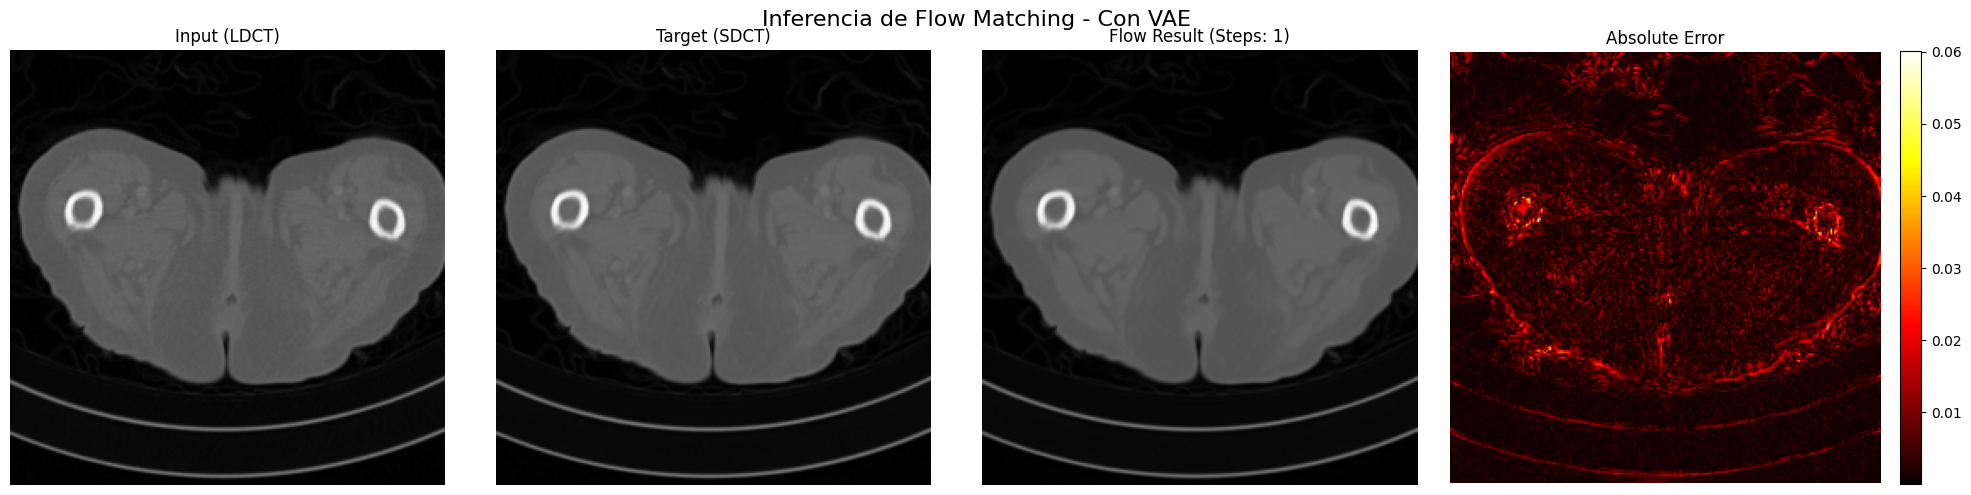

In [13]:

plot_flow_inference_vae(vae, model, data_item, device, 1)

PSNR: 55.35 dB, SSIM: 0.9977


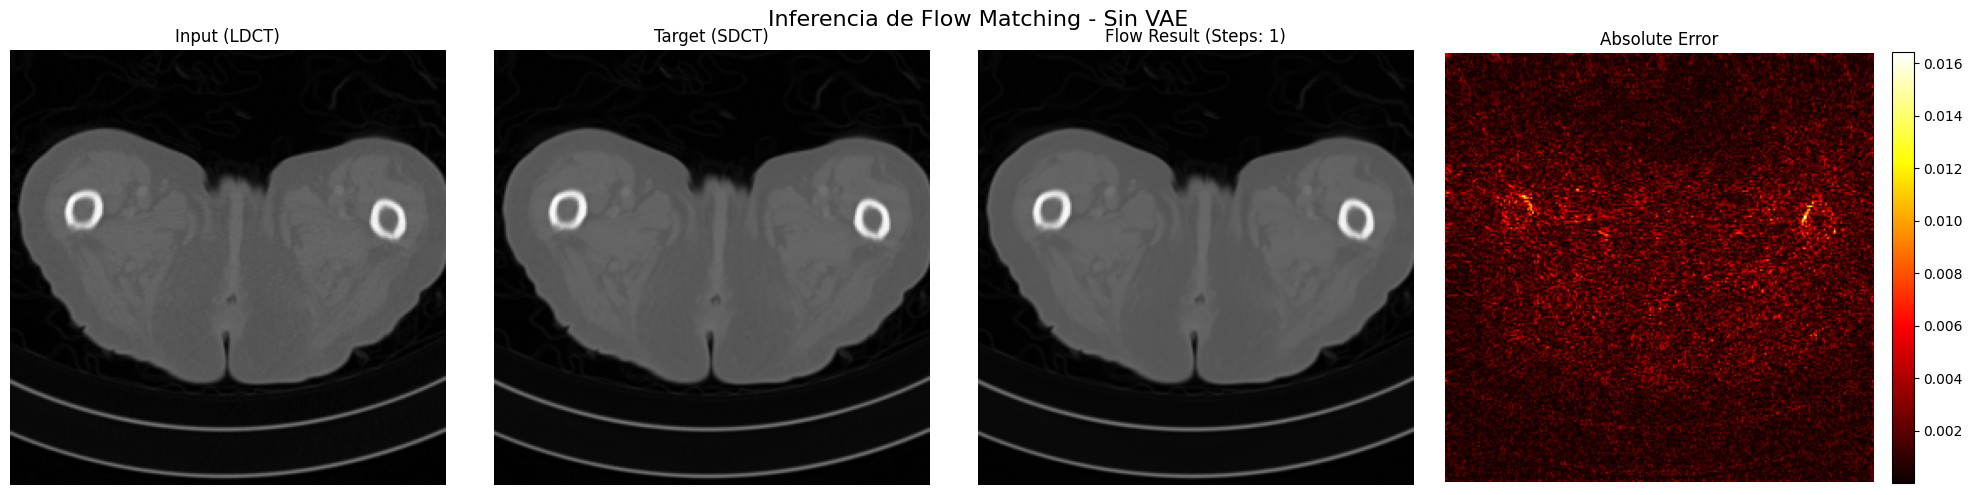

In [14]:

plot_flow_inference_model(model2, data_item, device, 1)

### Results

Total val data: 4205 slices

#### 1 paso:

con vae 3m | sin vae 5m 47s

Promedio PSNR con VAE: 41.39 dB | Promedio SSIM con VAE: 0.9627

Promedio PSNR sin VAE: 50.98 dB | Promedio SSIM sin VAE: 0.9864

#### 10 pasos:

con vae 12m 28s | sin vae 56m 16s

Promedio PSNR con VAE: 41.42 dB | Promedio SSIM con VAE: 0.9619

Promedio PSNR sin VAE: 50.20 dB | Promedio SSIM sin VAE: 0.9828

#### 50 pasos:

con vae 54m 39s | sin vae 288min 29s

Promedio PSNR con VAE: 41.41 dB | Promedio SSIM con VAE: 0.9617

Promedio PSNR sin VAE: 50.01 dB | Promedio SSIM sin VAE: 0.9817

## CLRM y MGC Evaluation

### Data loading

In [22]:
path_texts = [os.path.join("Dataset", "clrm_test.txt"), os.path.join("Dataset", "mgc_test.txt")]
clrm_dataset=pd.read_csv(path_texts[0], sep='\t', names=('Case','SDCT','LDCT',))
mgc_dataset=pd.read_csv(path_texts[1], sep='\t', names=('Case','SDCT','LDCT',))

In [ ]:
val_clrm_dataset = LDCTDataset(clrm_dataset, model_type="model")
val_mgc_dataset = LDCTDataset(mgc_dataset, model_type="model")

In [24]:
val_clrm_loader = DataLoader(val_clrm_dataset, batch_size=1, shuffle=True, num_workers=4, pin_memory=torch.cuda.is_available())
val_mgc_loader = DataLoader(val_mgc_dataset, batch_size=1, shuffle=True, num_workers=4, pin_memory=torch.cuda.is_available())

### Mean results data

In [ ]:
# Promedio PSNR y SSIM para el modelo con VAE
psnr_values_vae = []
ssim_values_vae = []

for batch in val_mgc_loader:
    psnr, ssim = plot_flow_inference_vae(vae, model, batch, device, num_steps=1, show_plots=False)
    psnr_values_vae.append(psnr)
    ssim_values_vae.append(ssim)

In [99]:
# Promedio PSNR y SSIM para el modelo sin VAE
psnr_values_model = []
ssim_values_model = []

for batch in val_mgc_loader:   
    psnr, ssim = plot_flow_inference_model(model2, batch, device, num_steps=1, show_plots=False)
    psnr_values_model.append(psnr)
    ssim_values_model.append(ssim)

In [100]:
print(f"Promedio PSNR con VAE: {np.mean(psnr_values_vae):.2f} dB")
print(f"Promedio SSIM con VAE: {np.mean(ssim_values_vae):.4f}")
print(f"Promedio PSNR sin VAE: {np.mean(psnr_values_model):.2f} dB")
print(f"Promedio SSIM sin VAE: {np.mean(ssim_values_model):.4f}")

Promedio PSNR con VAE: 41.25 dB
Promedio SSIM con VAE: 0.9666
Promedio PSNR sin VAE: 48.67 dB
Promedio SSIM sin VAE: 0.9843


### Random singular image

In [83]:
from random import randint

data_item = val_clrm_dataset.__getitem__(randint(0, len(val_clrm_dataset)-1))
data_item["LDCT"] = data_item["LDCT"].unsqueeze(0)
data_item["SDCT"] = data_item["SDCT"].unsqueeze(0)
print(f"Selected Case: {data_item['Case']}, Split Index: {data_item['split_idx']}")

Selected Case: CRLM-CT-1089, Split Index: 35


In [87]:
# plot_flow_inference_vae_model(vae, model, data_item, device, 1)

PSNR: 12.74 dB, SSIM: 0.6440


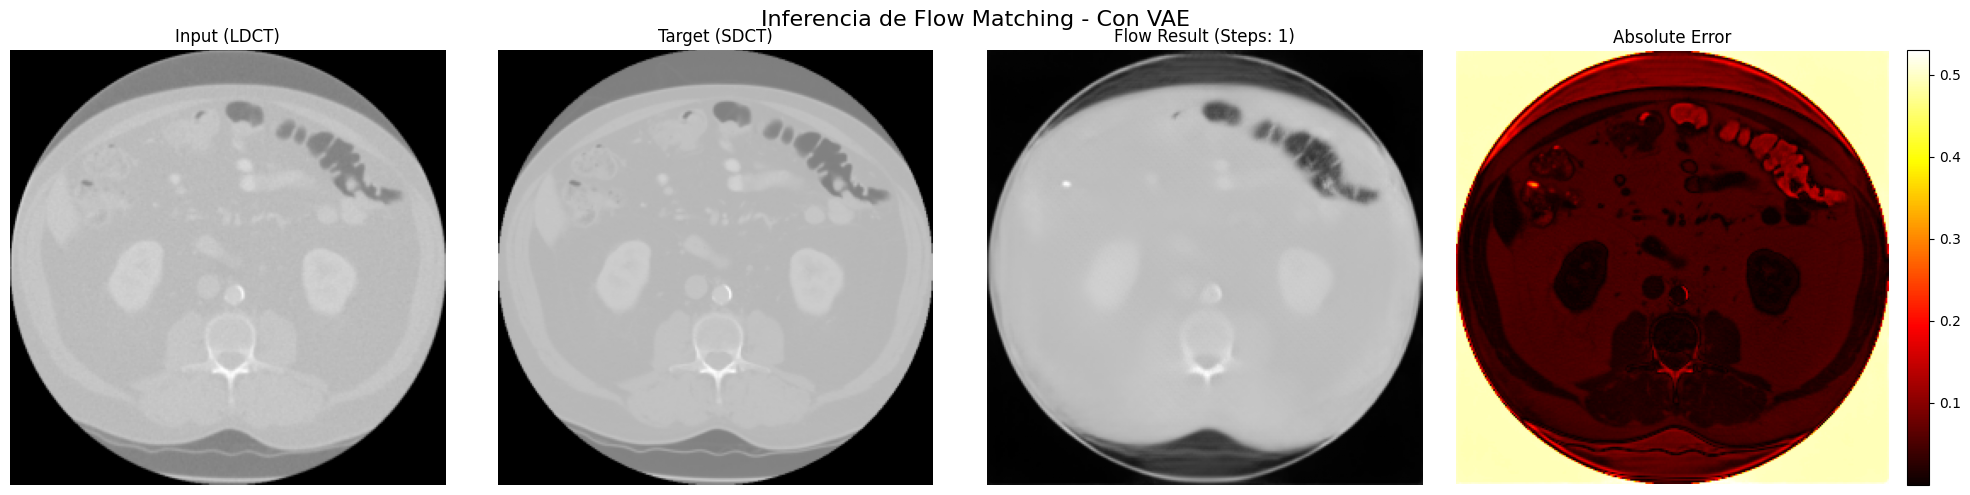

In [84]:
plot_flow_inference_vae(vae, model, data_item, device, 1)

PSNR: 26.09 dB, SSIM: 0.9315


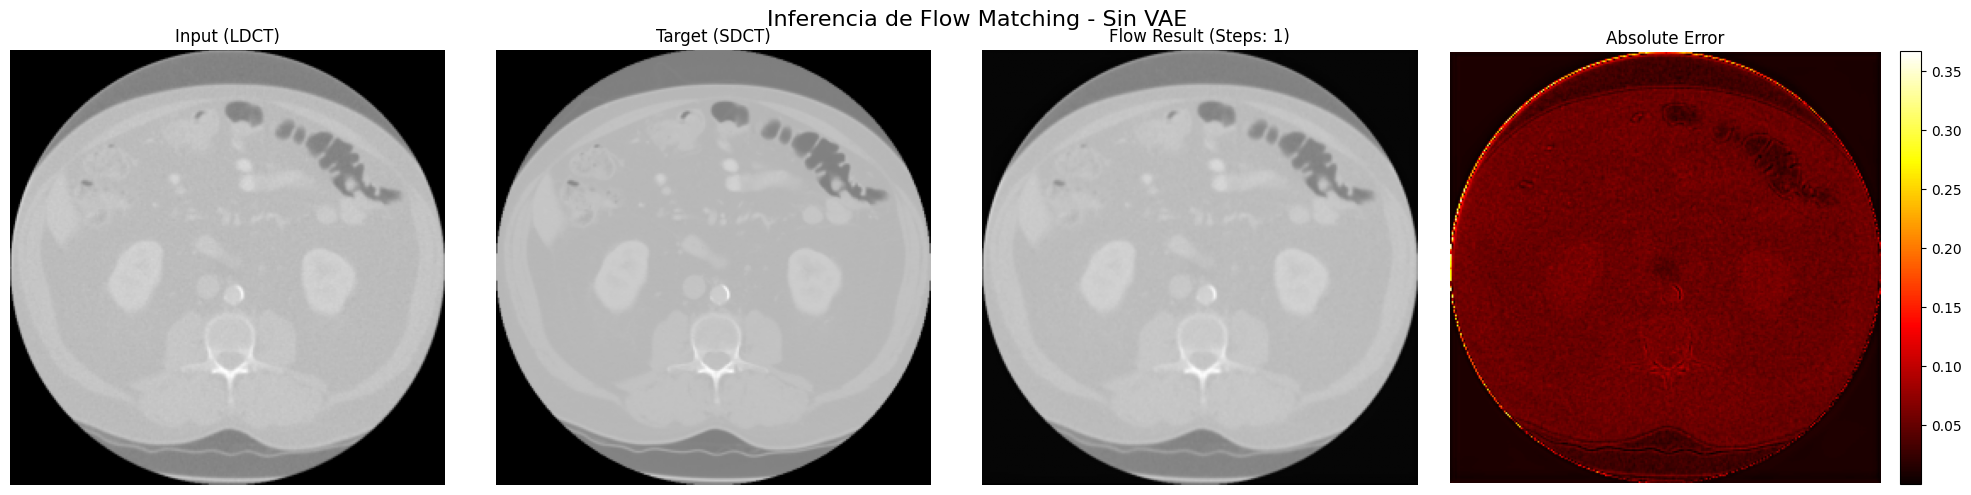

In [85]:
plot_flow_inference_model(model2, data_item, device, 1)

### Results

#### CLRM results

Total val data: 5406 slices

##### 1 paso:

con vae 3m 36s | sin vae 7m 15s

Promedio PSNR con VAE: 12.92 dB | Promedio SSIM con VAE: 0.4956

Promedio PSNR sin VAE: 32.19 dB | Promedio SSIM sin VAE: 0.8868

##### 10 pasos:

<!-- con vae 12m 28s | sin vae 56m 16s

Promedio PSNR con VAE: 41.42 dB | Promedio SSIM con VAE: 0.9619
 -->
<!-- Promedio PSNR sin VAE: 50.20 dB | Promedio SSIM sin VAE: 0.9828 -->

##### 50 pasos:

<!-- con vae 54m 39s | sin vae 288min 29s

Promedio PSNR con VAE: 41.41 dB | Promedio SSIM con VAE: 0.9617

Promedio PSNR sin VAE: 50.01 dB | Promedio SSIM sin VAE: 0.9817 -->

#### MGC Results

Total val data: 16628 slices

##### 1 paso:

con vae 77m 15s | sin vae 22m 18s

Promedio PSNR con VAE: 41.25 dB | Promedio SSIM con VAE: 0.9666

Promedio PSNR sin VAE: 48.67 dB | Promedio SSIM sin VAE: 0.9843

##### 10 pasos:

<!-- con vae 12m 28s | sin vae 56m 16s

Promedio PSNR con VAE: 41.42 dB | Promedio SSIM con VAE: 0.9619
 -->
<!-- Promedio PSNR sin VAE: 50.20 dB | Promedio SSIM sin VAE: 0.9828 -->

##### 50 pasos:

<!-- con vae 54m 39s | sin vae 288min 29s

Promedio PSNR con VAE: 41.41 dB | Promedio SSIM con VAE: 0.9617

Promedio PSNR sin VAE: 50.01 dB | Promedio SSIM sin VAE: 0.9817 -->